# GB1 Fitness Prediction: an Interview Walkthrough

**Question.** If we have measured only a few thousand protein variants, can a simple model *predict* the rest and *pick* promising candidates for the next round better than random choice?

**How to use this notebook**

| Mode | What to do |
|---|---|
| **Interview prep** (main use) | Read a section, then answer the **Interview check** out loud *before* opening the answer. Practise the *Say it simply* lines until they sound natural. |
| **Demo** (secondary) | *Run All* (about 3-5 minutes on a CPU, everything is seeded). The last section checks that the rerun matches the numbers I report. |

**What this is not.** A replay on data that already exists, for one protein, with a random split. It is not a wet-lab result, and it does not show the method transfers to other proteins.

**Data.** Wu et al. (2016), *Adaptation in protein fitness landscapes is facilitated by indirect paths*, eLife 5:e16965 (data CC BY 4.0), via the FLIP benchmark copy (github.com/J-SNACKKB/FLIP, modified files AFL-3.0).

## 0. The one-minute pitch

> A protein is a chain of building blocks, each written as a letter. In the GB1 dataset only **four** of those letters change, and a lab screen scored how well each of 149,361 versions works (the score is called *fitness*). I asked: given only **2,000** measured versions, can a simple model guess the others, and can it pick 20 good versions out of 20,000 untested ones better than picking at random? A small neural network put **19 of its 20 picks in the pool's top 1%** (random picking gives about 0.2). Two other random splits gave 15 and 17. It is a replay on existing data, so it shows the idea works *here*, not that it works on new proteins or in a new experiment.

Practise saying that in 60 seconds. The rest of the notebook is the evidence behind each sentence.

In [1]:
import os, sys, platform, urllib.request, zipfile, warnings
import numpy as np, pandas as pd
import torch, torch.nn as nn
import scipy, sklearn, matplotlib
import scipy.sparse as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from scipy.stats import spearmanr
from sklearn.linear_model import Ridge
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import Image, display

warnings.filterwarnings("ignore", message="An input array is constant")
torch.set_num_threads(4)

AA = "ACDEFGHIKLMNPQRSTVWY"                     # the 20 amino acids, one letter each
N_TRAIN, N_VAL, N_TEST, N_POOL = 2000, 2000, 5000, 20000
K = 20                                          # how many candidates we pick
SEED = 0                                        # main split; robustness check uses 0, 1, 2

# One palette for every figure: blue = Ridge, teal = Ridge+pairs, amber = neural net,
# crimson = true winners / top-1% line, grey = baseline / random.
BLUE, TEAL, AMBER, CRIMSON, GREY, DIAG, SLOT = "#4c78a8", "#59a89c", "#e8993e", "#d1495b", "#a9b2bf", "#6b7280", "#9b7bb8"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "figure.dpi": 110})
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scipy", scipy.__version__, "| sklearn", sklearn.__version__, "| torch", torch.__version__)

python 3.12.10 | numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | sklearn 1.9.1 | torch 2.15.0+cpu


## 1. The problem in plain words

* A **protein** is a long chain of building blocks (amino acids). Each block is written as one letter, so a protein looks like a very long word. **GB1** is one particular protein.
* In this dataset only **four slots** (positions 39, 40, 41, 54) are changed. Each slot can hold any of 20 letters, like a four-wheel combination lock: 20 x 20 x 20 x 20 = **160,000** combinations; 149,361 were measured.
* **VDGV** is the four letters the *natural* protein has in those slots (V at 39, D at 40, G at 41, V at 54). It is the reference. `VDAV` means the same protein with an A in the third slot instead of G.
* **One row of data = one four-letter combination + its measured score (fitness).** VDGV is defined to score exactly 1. A broken protein scores near 0.
* **Fitness is not** cell activation, a binding constant or a drug effect: it is a relative test-tube score that mixes "folds correctly" and "still binds its partner (IgG-Fc)".

**The model in one line:** input = four letters, output = a predicted score.

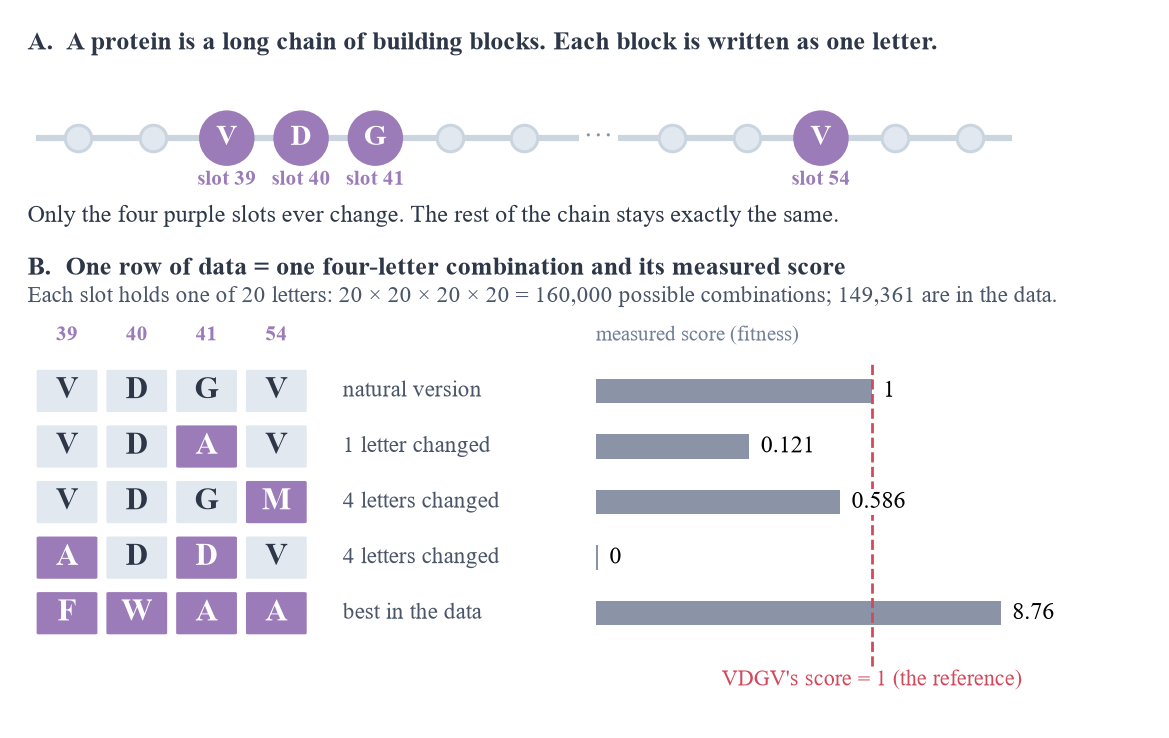

In [2]:
fig1 = "outputs/prep/fig1_rows.png"
if os.path.exists(fig1):
    display(Image(fig1, width=760))
else:
    print("(Conceptual figure not found; run from the repository root to see it.)")

> **Say it simply.** "Think of a four-wheel combination lock where each wheel has 20 letters. VDGV is the setting of the natural protein. Every other setting is a slightly different version, and the lab gave each one a score."

### Interview check 1
*Explain, in two sentences, what one row of the data is and what the model has to predict.*

<details><summary>Show answer</summary>

One row is one four-letter combination (the amino acids at four positions of GB1) and the fitness the lab measured for it. The model takes the four letters as input and predicts the fitness, a continuous number where 1 means "as good as the natural VDGV".
</details>

## 2. Look at the data before modelling

Always check size, missing values, duplicates and the shape of the target *before* choosing a model. The target's shape decides which metrics make sense.

In [3]:
DATA = "data/raw/four_mutations_full_data.csv"
URL = "https://github.com/J-SNACKKB/FLIP/raw/main/splits/gb1/four_mutations_full_data.csv.zip"
if not os.path.exists(DATA):                      # one-off download of the public FLIP copy
    os.makedirs("data/raw", exist_ok=True)
    urllib.request.urlretrieve(URL, DATA + ".zip")
    with zipfile.ZipFile(DATA + ".zip") as z:
        z.extract("four_mutations_full_data.csv", "data/raw")

# Only the 4-letter sequence (X) and Fitness (y). Count columns and split columns are NOT used:
# they are produced by the same measurement (or by someone else's split) and could leak the answer.
df = pd.read_csv(DATA, usecols=["Variants", "HD", "Fitness"])
assert df.Variants.is_unique and df.Variants.str.len().eq(4).all() and df.Fitness.notna().all()

print("rows:", len(df), "| missing:", int(df.isna().sum().sum()), "| duplicate variants:", int(df.Variants.duplicated().sum()))
hd = df.HD.value_counts().sort_index().rename("variants").to_frame()
hd["share"] = (hd.variants / len(df)).map("{:.1%}".format)
hd.index.name = "HD (letters different from VDGV)"
display(hd)
display(df.sample(5, random_state=0).reset_index(drop=True))

rows: 149361 | missing: 0 | duplicate variants: 0


,variants,share
HD (letters different from VDGV),,
0,1,0.0%
1,76,0.1%
2,2091,1.4%
3,26019,17.4%
4,121174,81.1%


,Variants,HD,Fitness
0,KEIR,4,0.002786
1,PLPN,4,0.000816
2,PRDE,4,0.001877
3,GGSL,4,0.000818
4,VWGW,2,2.357453


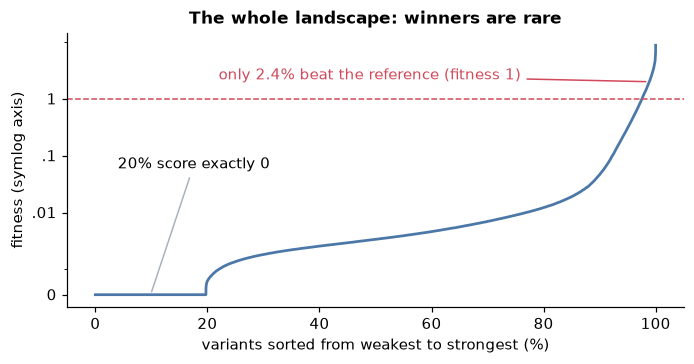

median fitness 0.0034 | mean 0.081 | max 8.76


In [4]:
fs = np.sort(df.Fitness.values); q = np.linspace(0, 100, len(fs))
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.plot(q, fs, color=BLUE, lw=1.8)
ax.set_yscale("symlog", linthresh=1e-3, linscale=0.4)
ax.axhline(1, color=CRIMSON, ls="--", lw=1)
ax.set_yticks([0, 1e-2, 1e-1, 1]); ax.set_yticklabels(["0", ".01", ".1", "1"])
ax.set_xlabel("variants sorted from weakest to strongest (%)"); ax.set_ylabel("fitness (symlog axis)")
zero_pct, beat_pct = (df.Fitness == 0).mean() * 100, (df.Fitness > 1).mean() * 100
ax.annotate(f"{zero_pct:.0f}% score exactly 0", xy=(zero_pct / 2, 0), xytext=(4, 0.06), arrowprops=dict(arrowstyle="-", color=GREY))
ax.annotate(f"only {beat_pct:.1f}% beat the reference (fitness 1)", xy=(100 - beat_pct / 2, 2), xytext=(22, 2.2),
            color=CRIMSON, arrowprops=dict(arrowstyle="-", color=CRIMSON))
ax.set_title("The whole landscape: winners are rare")
plt.tight_layout(); plt.show()
print(f"median fitness {df.Fitness.median():.4f} | mean {df.Fitness.mean():.3f} | max {df.Fitness.max():.2f}")

> **Say it simply.** "About a fifth of the versions are dead and only 2.4% beat the natural one. If a model just says 'about 0.01' for everything it is nearly right almost every time, yet useless for finding the good ones. So I judge models by whether they can *pick out the winners*, not only by average error."

### Interview check 2
*Why would "average error" alone be a misleading way to judge a model on this dataset?*

<details><summary>Show answer</summary>

Most variants score near 0, so a model that predicts "near 0" for everything gets a small average error while finding none of the rare high-fitness variants. The goal (choosing candidates) is a ranking-at-the-top problem, so I also report Spearman and, most importantly, how many of the picked candidates are truly in the top 1%.
</details>

## 3. Split the data into four separate groups

| Group | Size | Job | May steer model choices? |
|---|---|---|---|
| **Train** | 2,000 | the model learns from these | yes |
| **Validation** | 2,000 | pick settings, decide when to stop training | yes |
| **Test** | 5,000 | final report card, marked only once | **no** |
| **Pool** | 20,000 | stands in for *unmeasured* candidates; answers are hidden until the picks are made | **no** |

Analogy: practice questions, a mock exam used to adjust the study plan, the final exam, and sealed boxes opened only after you choose. One random shuffle is cut into consecutive blocks, so the groups cannot overlap.

In [5]:
def make_split(df, seed):
    perm = np.random.default_rng(seed).permutation(len(df))
    cuts = np.cumsum([N_TRAIN, N_VAL, N_TEST, N_POOL])
    parts = np.split(perm[:cuts[-1]], cuts[:-1])
    allidx = np.concatenate(parts)
    assert len(set(allidx)) == len(allidx), "sets overlap!"          # disjoint by construction, checked anyway
    return {n: df.iloc[p].reset_index(drop=True) for n, p in zip(["train", "val", "test", "pool"], parts)}

S = make_split(df, SEED)
summary = pd.DataFrame({n: {"n": len(d), "mean": d.Fitness.mean(), "median": d.Fitness.median(),
                            "share > 1": (d.Fitness > 1).mean(), "share = 0": (d.Fitness == 0).mean()} for n, d in S.items()}).T
display(summary.style.format({"n": "{:,.0f}", "mean": "{:.3f}", "median": "{:.4f}", "share > 1": "{:.1%}", "share = 0": "{:.1%}"}))
print(f"{sum(len(d) for d in S.values()):,} of {len(df):,} variants are used ({sum(len(d) for d in S.values()) / len(df):.0%}).")

,n,mean,median,share > 1,share = 0
train,"2,000",0.079,0.0034,2.2%,20.3%
val,"2,000",0.073,0.0033,2.3%,19.6%
test,"5,000",0.075,0.0034,2.5%,20.1%
pool,"20,000",0.076,0.0034,2.3%,19.7%


29,000 of 149,361 variants are used (19%).


The four groups look alike (about 2.3-2.5% winners in each), which is what a random split should give.

### Interview check 3
*Why four groups instead of two? What goes wrong if the test set helps choose the model?*

<details><summary>Show answer</summary>

Train learns the parameters, validation chooses settings and the stopping point, test is the one-time final grade, and the pool imitates "candidates we have not measured". If test (or pool) results steer any choice, the final numbers are no longer an honest estimate of performance on unseen data: that is data leakage / overfitting to the test set.
</details>

## 4. Turn letters into numbers (one-hot encoding)

A model cannot read letters. For each slot we create **20 on/off switches**, one per amino acid, and switch exactly one on. Four slots give **80 switches** per variant. We do *not* write A=1, C=2, ... because that would invent a fake ordering between amino acids. The alphabet is fixed, so nothing here is fitted on data.

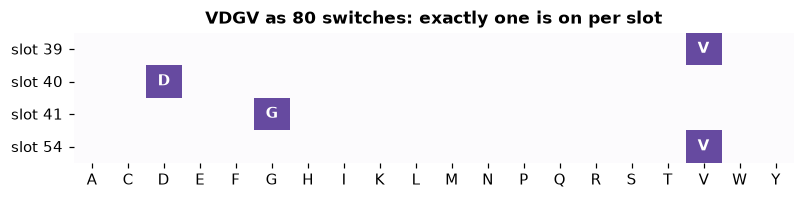

X shape: (2000, 80) | each row sums to [4. 4. 4.] (one letter per slot)


In [6]:
def onehot(seqs):
    X = np.zeros((len(seqs), 4 * 20), dtype=np.float32)
    for i, s in enumerate(seqs):
        for j, ch in enumerate(s):
            X[i, j * 20 + AA.index(ch)] = 1.0
    return X

x = onehot(["VDGV"])[0].reshape(4, 20)
fig, ax = plt.subplots(figsize=(7.4, 1.9))
ax.imshow(x, cmap="Purples", aspect="auto", vmin=0, vmax=1.3)
ax.set_xticks(range(20)); ax.set_xticklabels(list(AA)); ax.set_yticks(range(4)); ax.set_yticklabels(["slot 39", "slot 40", "slot 41", "slot 54"])
for j, ch in enumerate("VDGV"):
    ax.text(AA.index(ch), j, ch, ha="center", va="center", color="white", fontweight="bold")
ax.set_title("VDGV as 80 switches: exactly one is on per slot"); ax.spines[:].set_visible(False)
plt.tight_layout(); plt.show()

Xtr, Xva, Xte, Xpool = (onehot(S[n].Variants) for n in ["train", "val", "test", "pool"])
ytr, yva, yte, ypool = (S[n].Fitness.values.astype(np.float32) for n in ["train", "val", "test", "pool"])
print("X shape:", Xtr.shape, "| each row sums to", Xtr.sum(1)[:3], "(one letter per slot)")

### Interview check 4
*Why one-hot instead of numbering the amino acids 1 to 20?*

<details><summary>Show answer</summary>

Numbering would tell the model that, say, D (3) lies between C (2) and E (4) and that distances between numbers mean something. Amino-acid labels have no such numeric order. One-hot makes each letter an independent switch so the model learns a separate effect for each.
</details>

## 5. Three guessers, from lazy to clever

**Metrics used** (all computed on held-out data): **MAE** (average absolute error), **RMSE** (like MAE but punishes big misses more), **Spearman** (does the model rank variants in the right order?). For picking candidates, the decisive number is later: *how many picks are truly in the pool's top 1%*.

### 5a. Baseline: guess the training average for everyone

In [7]:
def metrics(y, p):
    return dict(MAE=float(np.mean(np.abs(y - p))), RMSE=float(np.sqrt(np.mean((y - p) ** 2))),
                Spearman=float(spearmanr(y, p)[0]) if np.std(p) > 0 else float("nan"))

results = {}
results["Training-average baseline"] = metrics(yte, np.full_like(yte, ytr.mean()))
print("training mean =", round(float(ytr.mean()), 4), "->", {k: round(v, 3) for k, v in results["Training-average baseline"].items()})

training mean = 0.0787 -> {'MAE': 0.13, 'RMSE': 0.381, 'Spearman': nan}


### 5b. Ridge: give every letter in every slot a point value, add them up

Ridge is linear regression plus a penalty that keeps the point values from getting extreme. The penalty strength `alpha` is chosen on **validation** data (by Spearman, since ranking is what we care about).

In [8]:
def fit_ridge(Xtr, ytr, Xva, yva, alphas=(0.01, 0.1, 1, 10, 100, 1000)):
    rows = [(a, metrics(yva, Ridge(alpha=a).fit(Xtr, ytr).predict(Xva))) for a in alphas]
    best = max(rows, key=lambda r: r[1]["Spearman"])[0]
    return Ridge(alpha=best).fit(Xtr, ytr), best, rows

ridge, alpha_best, sweep = fit_ridge(Xtr, ytr, Xva, yva)
display(pd.DataFrame({a: m for a, m in sweep}).T.rename_axis("alpha").round(4))
p_ridge_te, p_ridge_pool = ridge.predict(Xte), ridge.predict(Xpool)
results["One-hot + Ridge"] = metrics(yte, p_ridge_te)
print("chosen alpha:", alpha_best, "(validation Spearman barely changes across the range: the penalty matters little with 80 features)")

,MAE,RMSE,Spearman
alpha,,,
0.01,0.1688,0.3388,0.5026
0.10,0.1687,0.3388,0.5025
1.00,0.1677,0.3386,0.5022
10.00,0.1584,0.3376,0.4993
100.00,0.1199,0.3429,0.4847
1000.00,0.1238,0.3643,0.4679


chosen alpha: 0.01 (validation Spearman barely changes across the range: the penalty matters little with 80 features)


### 5c. A small neural network (PyTorch)

Same 80 switches in, a hidden layer of 64 units, another of 64, one number out. The training step is the same five moves every time:

1. **forward**: make predictions, 2. **loss**: measure how wrong, 3. **zero_grad**: clear old gradients, 4. **backward**: work out how each weight should change, 5. **step**: update the weights.

**Early stopping:** after each pass over the training data we measure the loss on *validation*; if it has not improved for 30 passes we stop and keep the best weights. That stops the network memorising the 2,000 training examples.

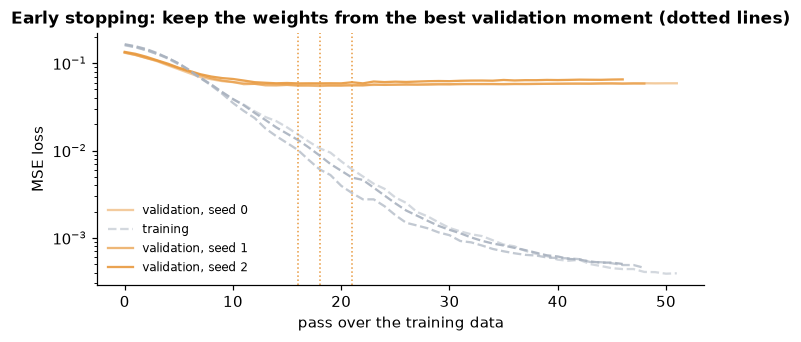

best epochs: [21, 18, 16] | stopped after: [52, 49, 47] passes


In [9]:
def make_mlp():
    return nn.Sequential(nn.Linear(80, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))

def train_mlp(seed, Xtr, ytr, Xva, yva, max_epochs=300, patience=30):
    torch.manual_seed(seed)
    model, loss_fn = make_mlp(), nn.MSELoss()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
    g = torch.Generator().manual_seed(seed)
    loader = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(ytr)), batch_size=128, shuffle=True, generator=g)
    Xv, yv = torch.tensor(Xva), torch.tensor(yva)
    best, best_state, bad, hist = float("inf"), None, 0, {"train": [], "val": []}
    for epoch in range(max_epochs):
        model.train(); running = 0.0
        for xb, yb in loader:
            pred = model(xb).squeeze(1)       # 1. forward
            loss = loss_fn(pred, yb)          # 2. loss
            opt.zero_grad()                   # 3. clear old gradients
            loss.backward()                   # 4. new gradients
            opt.step()                        # 5. update weights
            running += loss.item() * len(xb)
        model.eval()
        with torch.no_grad():                 # evaluation: no gradient bookkeeping
            v = loss_fn(model(Xv).squeeze(1), yv).item()
        hist["train"].append(running / len(Xtr)); hist["val"].append(v)
        if v < best - 1e-6:
            best, bad, best_state, best_epoch = v, 0, {k: t.clone() for k, t in model.state_dict().items()}, epoch
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(best_state); model.eval()
    return model, hist, best_epoch

def predict(model, X):
    with torch.no_grad():
        return model(torch.tensor(X)).squeeze(1).numpy()

nets = [train_mlp(s, Xtr, ytr, Xva, yva) for s in (0, 1, 2)]        # three different starting points
te_preds = np.array([predict(m, Xte) for m, _, _ in nets]); pool_preds = np.array([predict(m, Xpool) for m, _, _ in nets])
p_mlp_te, p_mlp_pool = te_preds.mean(0), pool_preds.mean(0)

fig, ax = plt.subplots(figsize=(6.4, 3.2))
for i, (m, h, be) in enumerate(nets):
    ax.plot(h["val"], color=AMBER, alpha=0.5 + 0.2 * i, label=f"validation, seed {i}")
    ax.plot(h["train"], color=GREY, alpha=0.5 + 0.2 * i, ls="--", label="training" if i == 0 else None)
    ax.axvline(be, color=AMBER, ls=":", lw=1)
ax.set_xlabel("pass over the training data"); ax.set_ylabel("MSE loss"); ax.set_yscale("log")
ax.set_title("Early stopping: keep the weights from the best validation moment (dotted lines)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

results["Neural net (single seed)"] = metrics(yte, te_preds[0])
results["Neural net (3-seed average)"] = metrics(yte, p_mlp_te)
print("best epochs:", [be for _, _, be in nets], "| stopped after:", [len(h["val"]) for _, h, _ in nets], "passes")

### Interview check 5
*Walk me through one training step. Then: what do `model.eval()` and `torch.no_grad()` each do?*

<details><summary>Show answer</summary>

Predict (forward), measure the error (loss), clear gradients left from the last step (`zero_grad`, otherwise they accumulate), compute new gradients by backpropagation (`backward`), update the weights (`step`).
`eval()` switches layers such as dropout to their testing behaviour (this small network has none, but it is the right habit). `no_grad()` turns off gradient bookkeeping, saving memory and ensuring evaluation never accidentally changes the model. They do different jobs and are not interchangeable.
</details>

*Why do the validation and training loss curves matter?*

<details><summary>Show answer</summary>

Training loss keeps falling as the network memorises. Validation loss falls, then stops improving or rises. The best validation point is the best guess for how it will do on new data, which is why we stop there.
</details>

## 6. Results on the test set (5,000 variants never used to choose anything)

In [10]:
def pair_feats(seqs):
    idx = np.array([[AA.index(c) for c in s] for s in seqs]); n = len(idx)
    rows, cols = [], []
    for j in range(4):                                   # the original 80 switches
        rows.append(np.arange(n)); cols.append(j * 20 + idx[:, j])
    base = 80
    for a in range(4):
        for b in range(a + 1, 4):                        # one 20x20 block per pair of slots: "letter X in slot a AND letter Y in slot b"
            rows.append(np.arange(n)); cols.append(base + idx[:, a] * 20 + idx[:, b]); base += 400
    r, c = np.concatenate(rows), np.concatenate(cols)
    return sp.csr_matrix((np.ones(len(r), dtype=np.float32), (r, c)), shape=(n, base))

Ptr, Pva, Pte, Ppool = (pair_feats(S[n].Variants) for n in ["train", "val", "test", "pool"])
ridge_pair, alpha_pair, _ = fit_ridge(Ptr, ytr, Pva, yva, alphas=(0.1, 0.3, 1, 3, 10, 30))
p_pair_te, p_pair_pool = ridge_pair.predict(Pte), ridge_pair.predict(Ppool)
results["One-hot + Ridge with position pairs"] = metrics(yte, p_pair_te)
print(f"pair features: {Ptr.shape[1]} switches (80 single + 6 pairs x 400), alpha = {alpha_pair}")

order = ["Training-average baseline", "One-hot + Ridge", "One-hot + Ridge with position pairs", "Neural net (single seed)", "Neural net (3-seed average)"]
res = pd.DataFrame(results).T.loc[order].round(3)
display(res)

pair features: 2480 switches (80 single + 6 pairs x 400), alpha = 30


,MAE,RMSE,Spearman
Training-average baseline,0.130,0.381,NaN
One-hot + Ridge,0.172,0.349,0.499
One-hot + Ridge with position pairs,0.128,0.325,0.509
Neural net (single seed),0.067,0.231,0.424
Neural net (3-seed average),0.062,0.230,0.461


*(The "position pairs" row is a diagnostic added to test why the network helps; section 8 explains it.)*

Numbers alone hide the story. The scatter plot shows **what each model predicts for each true score**; a perfect model sits on the dashed line.

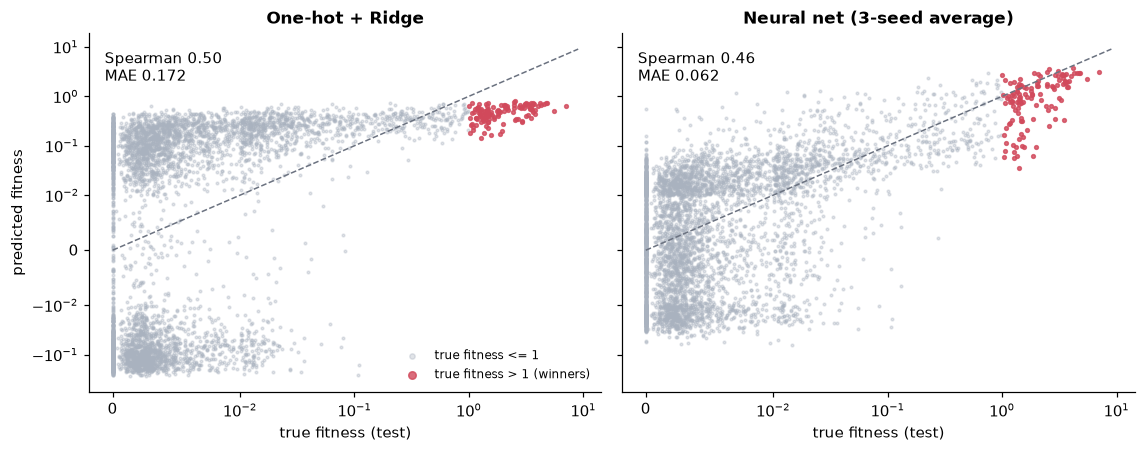

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
for a, p, t in [(axs[0], p_ridge_te, "One-hot + Ridge"), (axs[1], p_mlp_te, "Neural net (3-seed average)")]:
    hi = yte > 1
    a.scatter(yte[~hi], p[~hi], s=3, alpha=0.35, color=GREY, label="true fitness <= 1", rasterized=True)
    a.scatter(yte[hi], p[hi], s=6, alpha=0.8, color=CRIMSON, label="true fitness > 1 (winners)", rasterized=True)
    a.set_xscale("symlog", linthresh=1e-2); a.set_yscale("symlog", linthresh=1e-2)
    a.plot([0, 9], [0, 9], color=DIAG, lw=1, ls="--"); a.set_title(t); a.set_xlabel("true fitness (test)")
    m = metrics(yte, p); a.text(0.03, 0.95, f"Spearman {m['Spearman']:.2f}\nMAE {m['MAE']:.3f}", transform=a.transAxes, va="top")
axs[0].set_ylabel("predicted fitness"); axs[0].legend(loc="lower right", frameon=False, markerscale=2, fontsize=8)
plt.tight_layout(); plt.show()

**What to notice.** Ridge squeezes every winner to a prediction near 0.5, and it predicts *negative* fitness for many variants, which is impossible. The network puts the winners much closer to the dashed line.

### The puzzle: Ridge has a better Spearman than the network but a *worse MAE than guessing the average*. Why?

Split the test set by how good each variant really is and look at the error in each band.

,n variants,Training average,Ridge,Neural net
true fitness band,,,,
< 0.01,3855,0.076,0.120,0.016
0.01 - 0.1,799,0.053,0.192,0.060
0.1 - 1,223,0.286,0.188,0.327
> 1,123,2.059,1.650,1.011


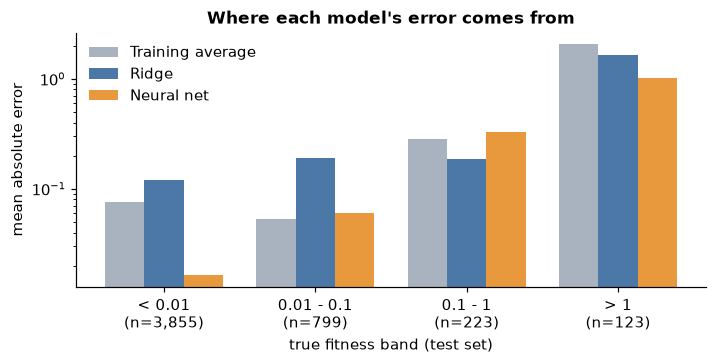

In [12]:
edges = [0, 0.01, 0.1, 1, np.inf]; labels = ["< 0.01", "0.01 - 0.1", "0.1 - 1", "> 1"]
band = np.digitize(yte, edges[1:-1])
preds = {"Training average": np.full_like(yte, ytr.mean()), "Ridge": p_ridge_te, "Neural net": p_mlp_te}
tab = pd.DataFrame({k: [np.abs(yte - p)[band == b].mean() for b in range(4)] for k, p in preds.items()}, index=labels)
tab.insert(0, "n variants", [int((band == b).sum()) for b in range(4)]); tab.index.name = "true fitness band"
display(tab.round(3))

fig, ax = plt.subplots(figsize=(6.6, 3.4)); w = 0.26
for k, (name, col) in enumerate([("Training average", GREY), ("Ridge", BLUE), ("Neural net", AMBER)]):
    ax.bar(np.arange(4) + (k - 1) * w, tab[name], w, label=name, color=col)
ax.set_xticks(range(4)); ax.set_xticklabels([f"{l}\n(n={n:,})" for l, n in zip(labels, tab["n variants"])])
ax.set_yscale("log"); ax.set_ylabel("mean absolute error"); ax.set_xlabel("true fitness band (test set)")
ax.legend(frameon=False); ax.set_title("Where each model's error comes from"); plt.tight_layout(); plt.show()

**Reading it.** In the two weakest bands (about 93% of the test set) Ridge is *worse than the baseline*: it hands out 0.1-0.4 to variants that are really near 0. MAE counts every variant equally, so those many small mistakes dominate. The network is **not** uniformly better either: in the 0.1-1 band it is slightly worse than the baseline.

My reading of why Spearman disagrees: it scores the whole ranking, and 77% of test variants score below 0.01, where the true order is a crowd of near-ties. So it hardly rewards getting the *top* right, which is the part the candidate-picking task needs.

> **Say it simply.** "One metric can hide a failure. Ridge looks fine on ranking but its average error is worse than guessing the mean, because it overestimates the dead majority."

### Interview check 6
*A teammate says "model A has the lower MAE, so it is better for choosing candidates". How do you respond?*

<details><summary>Show answer</summary>

MAE is dominated by the large number of near-zero variants and says little about the top of the ranking. For choosing candidates I look at ranking (Spearman) and, most directly, at how many of the model's top picks are truly in the top 1% of the pool. A model can have a good MAE and still miss the winners.
</details>

## 7. The candidate round: pick 20, then reveal

**Rule fixed before looking.** Each strategy picks the **20 highest predicted** variants from the 20,000-variant pool. Only then are the true values revealed. A **hit** is a pick whose true fitness is in the pool's **top 1%**. Random picking is repeated 5,000 times for a fair comparison. The result is never used to choose or tune a model.

In [13]:
thr = np.quantile(ypool, 0.99)                                  # "hit" threshold: top 1% of the pool
def score(y, idx, thr):
    return dict(mean_fitness=float(y[idx].mean()), hits=int((y[idx] >= thr).sum()))

picks = {"Ridge": np.argsort(-p_ridge_pool)[:K], "Ridge + pairs": np.argsort(-p_pair_pool)[:K],
         "Neural net": np.argsort(-p_mlp_pool)[:K], "Oracle (ceiling)": np.argsort(-ypool)[:K]}
cand = {k: score(ypool, ix, thr) for k, ix in picks.items()}
rng = np.random.default_rng(123)
rand = [score(ypool, rng.choice(len(ypool), K, replace=False), thr) for _ in range(5000)]
rm, rh = np.array([r["mean_fitness"] for r in rand]), np.array([r["hits"] for r in rand])
cand["Random (5,000 draws, average)"] = dict(mean_fitness=float(rm.mean()), hits=float(rh.mean()))
cdf = pd.DataFrame(cand).T[["hits", "mean_fitness"]]
display(cdf.round(3))
print(f"hit threshold (pool top 1%) = {thr:.3f} | expected random hits = {K * 0.01:.1f} | "
      f"95th percentile of random hits = {np.percentile(rh, 95):.0f} | best of 5,000 random draws = {rh.max()}")

,hits,mean_fitness
Ridge,13.000,2.854
Ridge + pairs,12.000,2.875
Neural net,19.000,3.726
Oracle (ceiling),20.000,5.062
"Random (5,000 draws, average)",0.191,0.074


hit threshold (pool top 1%) = 2.028 | expected random hits = 0.2 | 95th percentile of random hits = 1 | best of 5,000 random draws = 4


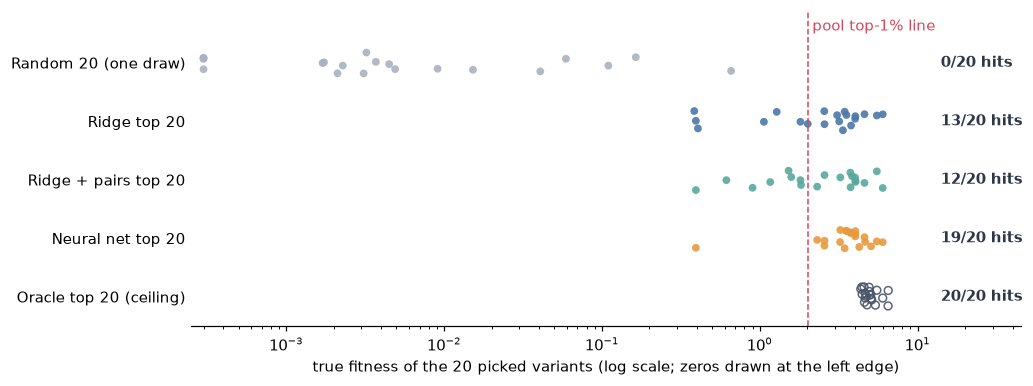

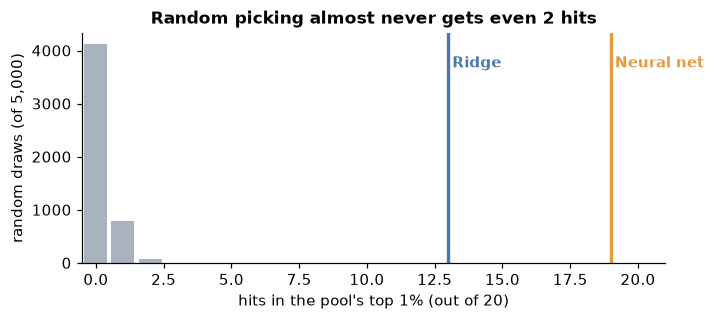

In [14]:
rng2 = np.random.default_rng(7)
groups = [("Random 20 (one draw)", np.random.default_rng(1).choice(len(ypool), K, replace=False), GREY),
          ("Ridge top 20", picks["Ridge"], BLUE), ("Ridge + pairs top 20", picks["Ridge + pairs"], TEAL),
          ("Neural net top 20", picks["Neural net"], AMBER), ("Oracle top 20 (ceiling)", picks["Oracle (ceiling)"], "#4a5568")]
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for i, (n, ix, col) in enumerate(groups):
    y = ypool[ix]; hollow = n.startswith("Oracle")
    ax.scatter(np.maximum(y, 3e-4), np.full(K, i) + rng2.uniform(-0.18, 0.18, K), s=26, facecolor="none" if hollow else col,
               edgecolor=col if hollow else "none", alpha=0.9)
    ax.text(14, i, f"{int((y >= thr).sum())}/20 hits", va="center", fontweight="bold", color="#2d3748")
ax.axvline(thr, color=CRIMSON, ls="--", lw=1); ax.text(thr * 1.06, -0.62, "pool top-1% line", color=CRIMSON, va="center")
ax.set_xscale("log"); ax.set_xlim(2.5e-4, 45); ax.set_ylim(4.5, -0.9)
ax.set_yticks(range(len(groups))); ax.set_yticklabels([g[0] for g in groups]); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("true fitness of the 20 picked variants (log scale; zeros drawn at the left edge)")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.hist(rh, bins=np.arange(-0.5, 8.5, 1), color=GREY, rwidth=0.85)
for name, col in [("Ridge", BLUE), ("Neural net", AMBER)]:
    ax.axvline(cand[name]["hits"], color=col, lw=2.2); ax.text(cand[name]["hits"] + 0.15, ax.get_ylim()[1] * 0.85, name, color=col, fontweight="bold")
ax.set_xlim(-0.5, 21); ax.set_xlabel("hits in the pool's top 1% (out of 20)"); ax.set_ylabel("random draws (of 5,000)")
ax.set_title("Random picking almost never gets even 2 hits"); plt.tight_layout(); plt.show()

> **Say it simply.** "If I pick 20 variants at random I expect about 0.2 winners. The network's 20 picks contained 19. The sealed-box rule means the answers were hidden until after the picking."

### Interview check 7
*How do you know the candidate result is not just luck, or leakage from using the answers?*

<details><summary>Show answer</summary>

(1) The pool's true values are not used by any model or setting; they are only read after the 20 picks are fixed. (2) Random picking is repeated 5,000 times, so luck is measured: even the best random draw gets only a handful of hits. (3) The scoring rule was fixed before looking. (4) I repeat the whole thing on two more random splits (section 10). What I still cannot rule out is that a random split is easier than real-world generalisation.
</details>

## 8. Why does the network beat plain Ridge?

**My first guess:** the four positions *interact*. Whether a letter is good depends on the letters beside it, which an "add up each letter's score" model cannot express.

**Test:** give Ridge every *pair* of slots as extra switches ("letter X in slot a AND letter Y in slot b"; 2,480 switches in total). If interactions explain the gap, Ridge should catch up. (Table in section 6 and the "Ridge + pairs" strip above.)

In [15]:
show = pd.DataFrame({
    "MAE": {k: results[k]["MAE"] for k in ["One-hot + Ridge", "One-hot + Ridge with position pairs", "Neural net (3-seed average)"]},
    "Spearman": {k: results[k]["Spearman"] for k in ["One-hot + Ridge", "One-hot + Ridge with position pairs", "Neural net (3-seed average)"]},
    "hits (of 20)": {"One-hot + Ridge": cand["Ridge"]["hits"], "One-hot + Ridge with position pairs": cand["Ridge + pairs"]["hits"],
                     "Neural net (3-seed average)": cand["Neural net"]["hits"]}})
display(show.round(3))

,MAE,Spearman,hits (of 20)
One-hot + Ridge,0.172,0.499,13
One-hot + Ridge with position pairs,0.128,0.509,12
Neural net (3-seed average),0.062,0.461,19


**Verdict (seed 0 alone is not enough, see section 10):** pair features fix Ridge's MAE problem, but on this split the top-20 picks do not improve (12 vs 13 hits); the network still leads (19). Across the three splits, Ridge + pairs gets close to the network on two of them. So interactions explain **much** of the gap but **not all** of it, and I have not tested what else is going on. Say exactly that.

### Interview check 8
*Why might a neural network beat Ridge here, and how did you check it?*

<details><summary>Show answer</summary>

Hypothesis: letters at the four slots interact, and a linear add-up model cannot represent that while a hidden layer can. I tested it by giving Ridge all pairwise slot-combination features. That fixed Ridge's average-error problem and brought its candidate hits close to the network on two of three splits, but not on split 0, so interactions are part, not all, of the explanation. I did not tune the network much, so I claim "better in this setup", not "networks beat linear models".
</details>

## 9. Can I trust a single prediction? A simple warning light

I trained the *same* network from three different random starting points. Where they **disagree**, the average prediction should be less reliable.

Spearman(disagreement, |error|) = 0.35
median |error|: calmest quarter = 0.0098 | most disputed quarter = 0.0286


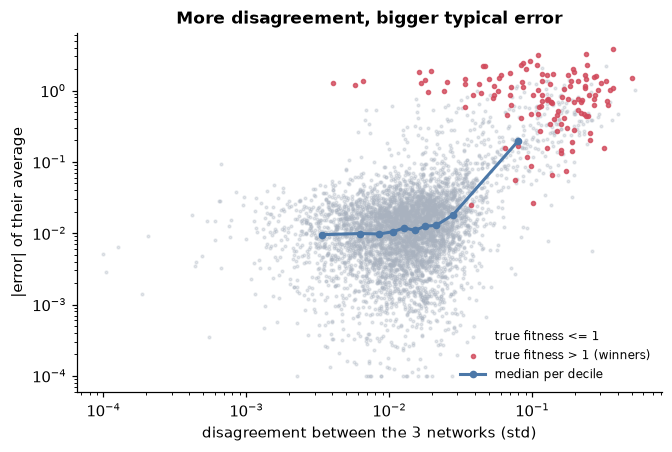

In [16]:
std_te = te_preds.std(0); abs_err = np.abs(yte - p_mlp_te)
rho = spearmanr(std_te, abs_err)[0]; qs = np.quantile(std_te, [0.25, 0.75])
print(f"Spearman(disagreement, |error|) = {rho:.2f}")
print(f"median |error|: calmest quarter = {np.median(abs_err[std_te <= qs[0]]):.4f} | most disputed quarter = {np.median(abs_err[std_te >= qs[1]]):.4f}")

hi = yte > 1; e, s_ = np.maximum(abs_err, 1e-4), np.maximum(std_te, 1e-4)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.scatter(s_[~hi], e[~hi], s=3, alpha=0.3, color=GREY, rasterized=True, label="true fitness <= 1")
ax.scatter(s_[hi], e[hi], s=7, alpha=0.8, color=CRIMSON, rasterized=True, label="true fitness > 1 (winners)")
bins = np.quantile(s_, np.linspace(0, 1, 11)); mx, my = [], []
for lo, up in zip(bins[:-1], bins[1:]):
    m = (s_ >= lo) & (s_ <= up); mx.append(np.median(s_[m])); my.append(np.median(e[m]))
ax.plot(mx, my, color=BLUE, lw=2, marker="o", ms=4, label="median per decile")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("disagreement between the 3 networks (std)"); ax.set_ylabel("|error| of their average")
ax.legend(frameon=False, loc="lower right", fontsize=8); ax.set_title("More disagreement, bigger typical error"); plt.tight_layout(); plt.show()

**The limit.** The three networks saw the same 2,000 examples. If they all misunderstand the same thing they agree *and* are all wrong. This is a rough warning light, **not** a confidence interval, and it ignores noise in the lab measurements.

### Interview check 9
*What does the disagreement tell you, and what does it not?*

<details><summary>Show answer</summary>

It tells me where the models are unsure because of their random starting point: higher disagreement goes with larger typical errors (Spearman about 0.35). It does not give calibrated intervals, does not include experimental noise, and cannot detect cases where all networks make the same mistake.
</details>

## 10. Is it just this one split? Repeat on three random splits

Everything above is packaged in one function and rerun for split seeds 0, 1 and 2. The seed-0 row must match the numbers shown earlier (a reproducibility check).

In [17]:
def run_split(seed):
    S_ = make_split(df, seed)
    Xt, Xv, Xs, Xp = (onehot(S_[n].Variants) for n in ["train", "val", "test", "pool"])
    yt, yv, ys, yp = (S_[n].Fitness.values.astype(np.float32) for n in ["train", "val", "test", "pool"])
    thr_ = np.quantile(yp, 0.99)
    rdg, _, _ = fit_ridge(Xt, yt, Xv, yv)
    Pt, Pv, Ps, Pp = (pair_feats(S_[n].Variants) for n in ["train", "val", "test", "pool"])
    rdp, _, _ = fit_ridge(Pt, yt, Pv, yv, alphas=(0.1, 0.3, 1, 3, 10, 30))
    ns = [train_mlp(s, Xt, yt, Xv, yv)[0] for s in (0, 1, 2)]
    pool_mlp = np.mean([predict(m, Xp) for m in ns], axis=0); te_mlp = np.mean([predict(m, Xs) for m in ns], axis=0)
    hits = lambda p: int((yp[np.argsort(-p)[:K]] >= thr_).sum())
    r = np.random.default_rng(123)
    rnd = np.mean([(yp[r.choice(len(yp), K, replace=False)] >= thr_).sum() for _ in range(5000)])
    return {"random hits": rnd, "Ridge hits": hits(rdg.predict(Xp)), "Ridge+pairs hits": hits(rdp.predict(Pp)), "Net hits": hits(pool_mlp),
            "Ridge MAE": metrics(ys, rdg.predict(Xs))["MAE"], "Ridge+pairs MAE": metrics(ys, rdp.predict(Ps))["MAE"],
            "Net MAE": metrics(ys, te_mlp)["MAE"], "Baseline MAE": metrics(ys, np.full_like(ys, yt.mean()))["MAE"]}

robust = pd.DataFrame({s: run_split(s) for s in (0, 1, 2)}).T.rename_axis("split seed")
display(robust.round(3))

# reproducibility check: the packaged function must reproduce the step-by-step numbers above
assert robust.loc[0, "Net hits"] == cand["Neural net"]["hits"] and robust.loc[0, "Ridge hits"] == cand["Ridge"]["hits"]
assert robust.loc[0, "Ridge+pairs hits"] == cand["Ridge + pairs"]["hits"]
assert abs(robust.loc[0, "Net MAE"] - results["Neural net (3-seed average)"]["MAE"]) < 1e-6
print("Reproducibility check passed: split seed 0 matches the step-by-step run.")

,random hits,Ridge hits,Ridge+pairs hits,Net hits,Ridge MAE,Ridge+pairs MAE,Net MAE,Baseline MAE
split seed,,,,,,,,
0,0.191,13.0,12.0,19.0,0.172,0.128,0.062,0.130
1,0.213,10.0,15.0,15.0,0.163,0.128,0.071,0.136
2,0.197,4.0,16.0,17.0,0.160,0.125,0.070,0.134


Reproducibility check passed: split seed 0 matches the step-by-step run.


**Reading it.** The network gets about 15-19 hits out of 20 on every split, against about 0.2 expected for random picking. Plain Ridge varies a lot (4 to 13). Ridge with pair features is close to the network on two of three splits. The baseline MAE sits near 0.13 everywhere, and the network's MAE is about half of it.

## 11. What the results do and do not say

| Claim | Status | Why |
|---|---|---|
| The network picks far better than random in this replay | **Supported** | 15-19 hits of 20 on three splits vs about 0.2 by chance |
| The network beats Ridge | **Partly** | Clear over plain Ridge; Ridge + position pairs is close on two of three splits |
| It works on sequences far from the training data | **Not tested** | The split was random; a split by distance from the training sequences is the honest next test |
| It transfers to other proteins, immune receptors or cells | **Not shown** | One protein, four positions, one test-tube assay |
| It would find winners in a real new experiment round | **Not shown** | This is a replay; the answers already existed in the data |
| Fitness 0 means a useless protein | **Unsafe** | A 0 can come from very low read counts or a measurement floor |

## 12. Questions to rehearse

Try to answer each one out loud first.

<details><summary><b>Why a random split, and is it fair?</b></summary>

It is the simplest honest start, but it flatters the model: test and training variants come from the same pool of letter combinations. A split by distance from the training sequences would be tougher and closer to real use. I have not done it, so I do not claim generalisation to distant sequences.
</details>

<details><summary><b>Why regression instead of "good vs bad" classification?</b></summary>

Keeping the number keeps how *much* better a variant is. The cost is a skewed, hard-to-fit target, which I handle by also scoring ranking and top-20 hits.
</details>

<details><summary><b>Why did you not tune the network more?</b></summary>

The goal was a clear, fair comparison, not the best possible number. I only used early stopping. So the claim is "better in this setup".
</details>

<details><summary><b>What would you do with one more week?</b></summary>

(1) Split by distance from the training sequences. (2) Plot hits against training size (500 to 5,000) to show how much data is needed. (3) Pick some candidates for exploration, not only the highest predictions, to keep the next batch diverse.
</details>

<details><summary><b>How does this relate to engineering immune-cell receptors?</b></summary>

The workflow is the same shape (limited measured variants, predict, choose the next batch), but this dataset is one protein, four positions and a test-tube assay. I would not claim the numbers transfer; I would reuse the discipline: separate sets, a pre-agreed scoring rule, honest baselines, and stating what is not shown.
</details>

## 13. Environment and reproducibility

In [18]:
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| torch", torch.__version__, "| matplotlib", matplotlib.__version__)
print("Seeds: split seed", SEED, "(and 1, 2 for robustness); network seeds 0, 1, 2; random-pick generator seed 123.")
print("Sets:", {n: len(d) for n, d in S.items()}, "| candidates K =", K)

python 3.12.10 | numpy 2.5.4 | pandas 3.1.1 | scipy 1.18.1 | scikit-learn 1.9.1 | torch 2.15.0+cpu | matplotlib 3.11.2
Seeds: split seed 0 (and 1, 2 for robustness); network seeds 0, 1, 2; random-pick generator seed 123.
Sets: {'train': 2000, 'val': 2000, 'test': 5000, 'pool': 20000} | candidates K = 20


**Reproduce:** `pip install -r requirements.txt`, then *Run All* from the repository root (the data are downloaded once from the public FLIP copy). Seeds make results repeatable on the same package versions; they do not remove all randomness across machines or library versions.

**Source and licence.** Wu et al. (2016), eLife 5:e16965 (CC BY 4.0); FLIP benchmark copy, modified files AFL-3.0. Data files are not committed to this repository.